<a href="https://colab.research.google.com/github/bsyeol/26AI_project/blob/main/final/FDS_StageB_Seed0_Resume.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# FDS | Stage B GRU 예비 실험 (Seed 0, 1·2·7·14·30일)
**기존 런타임 종료 후 재개용 전체 노트북.** 새 Colab에서 GPU 연결 → Secrets의 `TABPFN_TOKEN` 접근 허용 → 모두 실행.

- Stage A 15개 결과가 Drive에 있어야 한다. 재학습하지 않는다.
- Stage B: LightGBM, TabPFN 3.5, Fine-tuned TabPFN 3.5 × 5기간 × Seed 0 = 최대 15회. 이미 완료된 모델 및 GRU 체크포인트는 재사용한다.
- 기존 Original 9,996건/38 양성, 80/20 fit/tune, validation calibration/평가 분리, 3시간 bin, 현재 bin 제외, 32차원 GRU, 기존 하이퍼파라미터 유지. Test 미사용.
- 기존 `SEEDS`, `WINDOW_DAYS`, `config.json`, `rows.npz`는 유지. 하드웨어만 달라진 경우 기본 허용하되 새 세션 환경을 별도 기록하고 시간 지표 비교에 주의한다. 소프트웨어/데이터/실험 설정 불일치 시 중단한다.
- 출력 폴더: 기존 `gru_tabpfn35_original_daily_v2_full`, 예비 요약은 그 아래 `pilot_seed0/`. 같은 폴더를 다른 런타임에서 동시에 실행하지 않는다.
- 단일 seed 예비 결과이므로 최적 기간/통계적 강건성 확정 금지. 기존 실험의 평가 조건 그대로 사용.
- 새 런타임에서 실제 GPU 실행은 검증되지 않았다. 실행 중 종료되면 다시 모두 실행한다. 완료 JSON/NPZ는 보존되지만 미완료 분류기의 학습 가중치는 저장되지 않는다.


In [8]:
# 1. Colab 설치: 기존 실험 버전 유지
import subprocess, sys
from importlib.metadata import version, PackageNotFoundError
packages={'tabpfn':'10.2.0','lightgbm':'4.7.0','pyarrow':'26.0.1'}
need=[]
for p,v in packages.items():
    try: installed=version(p)
    except PackageNotFoundError: installed=None
    if installed!=v: need.append(f'{p}=={v}')
if need: subprocess.check_call([sys.executable,'-m','pip','install','-q',*need])
# 이미 import된 패키지가 변경됐다면 런타임 재시작

In [9]:
# 2. 환경/설정 — 기존 결과 경로 및 실험 조건 유지
from google.colab import drive, userdata
import os, json, gc, time, hashlib, inspect, platform, random, uuid
from pathlib import Path
from importlib.metadata import version
import numpy as np
import pandas as pd
import torch
from torch import nn
import lightgbm as lgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import average_precision_score, precision_recall_curve, auc, roc_curve
from tabpfn import TabPFNClassifier
from tabpfn.constants import ModelVersion
from tabpfn.finetuning.finetuned_classifier import FinetunedTabPFNClassifier
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

drive.mount('/content/drive')
ROOT=Path('/content/drive/MyDrive/26-2_AI_project/processed/full')
SMOKE=False  # 기존 본 실험과 동일
RUN_DAYS=[1,2,7,14,30]
RUN_SEEDS=[0]
ALLOW_HARDWARE_CHANGE=True  # CPU/GPU 차이만 허용; 시간은 직접 비교 금지
RATIO='Original'  # 원본 비율 고정
WINDOW_DAYS=list(range(91))  # 0: baseline, 1~90: 매일 GRU
SEEDS=[0,1,2,3,4]
EVAL_NEG_FRAC=1.0  # 본 실험은 전수 평가; 빠른 예비 실험만 .2 (가중 지표)
TUNE_N=50000
TARGET_FPR=.001
REVIEW_TARGET_RECALL=.30  # 동일 Recall 비교용 목표: 30%, 필요 시 변경 (운영 기준 아님)
assert 0 < REVIEW_TARGET_RECALL <= 1
LATENCY_LIMIT=100.
LATENCY_REPEATS=20; LATENCY_WARMUPS=3
HIDDEN=32; GRU_EPOCHS=20; GRU_PATIENCE=3; GRU_LR=1e-3; GRU_BATCH=256
FT_EPOCHS=10; FT_LR=1e-5; FT_EPISODE=4096; FT_PATIENCE=3  # Original의 희소 양성 고려
FT_TRAIN_EST=1; FINAL_EST=4; FT_VAL_EST=1
PRED_BATCH=4096
MAX_TREES=2000; LGB_PATIENCE=50
THREADS=min(8,len(os.sched_getaffinity(0)))
MODELS=['LightGBM','TabPFN 3.5','TabPFN 3.5 FT']
assert torch.cuda.is_available(), 'GPU 런타임 필요'
assert hasattr(ModelVersion,'V3_5'), 'TabPFN 3.5 버전 필요'
# 라이브러리 버전별 API 불일치를 초기에 확인 (모델 자동 대체 금지)
ft_args=set(inspect.signature(FinetunedTabPFNClassifier).parameters)
required={'model_version','extra_classifier_kwargs','epochs','learning_rate','n_finetune_ctx_plus_query_samples','n_estimators_finetune','n_estimators_validation','n_estimators_final_inference','early_stopping_patience','eval_metric','random_state','use_activation_checkpointing','validation_split_ratio','device'}
assert required <= ft_args, f'Fine-tuning API 불일치: {required-ft_args}'
assert {'X_val','y_val'} <= set(inspect.signature(FinetunedTabPFNClassifier.fit).parameters), '외부 validation 지원 API 필요'
if not os.environ.get('TABPFN_TOKEN'):
    for k in ('TABPFN_TOKEN','TABPFN_API_KEY'):
        try: token=userdata.get(k)
        except Exception: continue
        if token: os.environ['TABPFN_TOKEN']=token; del token; break
assert os.environ.get('TABPFN_TOKEN'), 'Colab Secrets 인증 키 확인'
if SMOKE: WINDOW_DAYS=[0,1]; SEEDS=[0]; GRU_EPOCHS=2; FT_EPOCHS=1; EVAL_NEG_FRAC=.01; LATENCY_REPEATS=3
assert RATIO=='Original' and 0<EVAL_NEG_FRAC<=1
OUT=ROOT/('gru_tabpfn35_original_daily_v2'+('_smoke' if SMOKE else '_full'))
OUT.mkdir(parents=True,exist_ok=True)
(OUT/'runs').mkdir(exist_ok=True)
(OUT/'embeddings').mkdir(exist_ok=True)
S=json.loads((ROOT/'settings.json').read_text(encoding='utf-8'))
BASE=S['BASE_FEATURES']; CAT=S['CATEGORICAL_FEATURES']; LABEL=S['LABEL']; USER=S['USER']; CAT_IDX=[BASE.index(c) for c in CAT]
assert len(BASE)==7 and set(SEEDS)<=set(S['SEEDS'])
assert '거래금액_로그' in BASE and '매체구분' in CAT
DEVICE='cuda'; SESSION=uuid.uuid4().hex[:12]
ENV=dict(gpu=torch.cuda.get_device_name(0),vram=int(torch.cuda.get_device_properties(0).total_memory),cpu=next((x.split(':',1)[1].strip() for x in Path('/proc/cpuinfo').read_text().splitlines() if x.startswith('model name')),platform.processor()),threads=THREADS,python=platform.python_version(),cuda=torch.version.cuda,versions={p:version(p) for p in ['tabpfn','torch','lightgbm','numpy','pandas','scikit-learn','pyarrow']})
def sha(p):
    h=hashlib.sha256()
    with open(p,'rb') as f:
        for b in iter(lambda:f.read(2**20),b''): h.update(b)
    return h.hexdigest()
def write_json(p,obj):
    tmp=p.with_suffix(p.suffix+'.tmp'); tmp.write_text(json.dumps(obj,ensure_ascii=False,indent=2,allow_nan=False),encoding='utf-8'); os.replace(tmp,p)
def write_csv(p,obj):
    tmp=p.with_suffix(p.suffix+'.tmp'); obj.to_csv(tmp,index=False); os.replace(tmp,p)
def write_npz(path,**kw):
    tmp=path.with_suffix(path.suffix+'.tmp')
    with open(tmp,'wb') as f: np.savez_compressed(f,**kw)
    os.replace(tmp,path)
CONFIG=dict(data_sha=sha(ROOT/'full_v1.parquet'),settings_sha=sha(ROOT/'settings.json'),design='original_9996_shared_fit_80_tune_20_daily_v2',ratio=RATIO,days=WINDOW_DAYS,seeds=SEEDS,base=BASE,cat=CAT,label=LABEL,user=USER,eval_fraction=EVAL_NEG_FRAC,tune_n=TUNE_N,target_fpr=TARGET_FPR,latency_repeats=LATENCY_REPEATS,latency_warmups=LATENCY_WARMUPS,hidden=HIDDEN,gru_epochs=GRU_EPOCHS,gru_patience=GRU_PATIENCE,gru_lr=GRU_LR,gru_batch=GRU_BATCH,ft_epochs=FT_EPOCHS,ft_lr=FT_LR,ft_episode=FT_EPISODE,ft_patience=FT_PATIENCE,ft_train_est=FT_TRAIN_EST,ft_val_est=FT_VAL_EST,final_est=FINAL_EST,pred_batch=PRED_BATCH,max_trees=MAX_TREES,lgb_patience=LGB_PATIENCE,env=ENV,smoke=SMOKE)
cp=OUT/'config.json'
assert cp.exists(), f'기존 config.json 없음: {cp}. ROOT 경로를 확인하세요.'
OLD_CONFIG=json.loads(cp.read_text())
old_design={k:v for k,v in OLD_CONFIG.items() if k!='env'}
new_design={k:v for k,v in CONFIG.items() if k!='env'}
diff=[k for k in sorted(old_design.keys() | new_design.keys()) if old_design.get(k)!=new_design.get(k)]
assert not diff, f'데이터/실험 설정 불일치: {diff}. 기존 config를 삭제하지 마세요.'
old_env=OLD_CONFIG['env']
hw_keys={'gpu','vram','cpu','threads'}
software_diff={k:(old_env.get(k),ENV.get(k)) for k in sorted(old_env.keys() | ENV.keys()) if k not in hw_keys and old_env.get(k)!=ENV.get(k)}
assert not software_diff, f'소프트웨어 환경 불일치: {software_diff}. 기존 config 버전으로 맞춘 뒤 재실행하세요.'
hardware_diff={k:(old_env.get(k),ENV.get(k)) for k in sorted(hw_keys) if old_env.get(k)!=ENV.get(k)}
assert ALLOW_HARDWARE_CHANGE or not hardware_diff, f'하드웨어 불일치: {hardware_diff}'
if hardware_diff: print('주의: 하드웨어 변경:',hardware_diff,'학습/추론 시간은 기존 세션과 직접 비교하지 마세요.')
assert set(RUN_DAYS)<=set(WINDOW_DAYS) and all(d>0 for d in RUN_DAYS)
assert set(RUN_SEEDS)<=set(SEEDS)
PILOT=OUT/'pilot_seed0'; PILOT.mkdir(exist_ok=True)
(OUT/'sessions').mkdir(exist_ok=True)
write_json(OUT/'sessions'/f'{SESSION}.json',dict(session=SESSION,env=ENV,hardware_diff=hardware_diff,run_days=RUN_DAYS,run_seeds=RUN_SEEDS,original_config=OLD_CONFIG))
print('현재 환경:',ENV)
print('기존 결과 경로:',OUT)
print('예비 실험:',RUN_DAYS,RUN_SEEDS,'최대',len(RUN_DAYS)*len(RUN_SEEDS)*len(MODELS),'회')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
주의: 하드웨어 변경: {'cpu': ('Intel(R) Xeon(R) CPU @ 2.00GHz', 'Intel(R) Xeon(R) CPU @ 2.20GHz'), 'gpu': ('Tesla T4', 'NVIDIA L4'), 'vram': (15637086208, 23659151360)} 학습/추론 시간은 기존 세션과 직접 비교하지 마세요.
현재 환경: {'gpu': 'NVIDIA L4', 'vram': 23659151360, 'cpu': 'Intel(R) Xeon(R) CPU @ 2.20GHz', 'threads': 8, 'python': '3.13.16', 'cuda': '13.0', 'versions': {'tabpfn': '10.2.0', 'torch': '2.14.1+cu130', 'lightgbm': '4.7.0', 'numpy': '2.4.6', 'pandas': '2.2.3', 'scikit-learn': '1.6.1', 'pyarrow': '26.0.1'}}
기존 결과 경로: /content/drive/MyDrive/26-2_AI_project/processed/full/gru_tabpfn35_original_daily_v2_full
예비 실험: [1, 2, 7, 14, 30] [0] 최대 15 회


In [10]:
# 3. 데이터 및 라벨 예산 분리
cols=list(dict.fromkeys(BASE+[LABEL,USER,'입금계좌일련번호','bin_id','split','date']))
df=pd.read_parquet(ROOT/'full_v1.parquet',columns=cols)
assert df.index.equals(pd.RangeIndex(len(df))) and not df[cols].isna().any().any()
y=df[LABEL].to_numpy(np.int8); bins=df['bin_id'].to_numpy(np.int64); split=df['split'].to_numpy()
assert set(np.unique(y))=={0,1}
train=np.flatnonzero(split=='train'); val=np.flatnonzero(split=='val')
assert bins[train].max()<bins[val].min(), '시간 분할 확인'
# 기존 Original V2와 동일 날짜 경계
dates=pd.to_datetime(df['date']).to_numpy()
val=val[np.argsort(dates[val],kind='stable')]; assert len(val)>TUNE_N
cut=np.searchsorted(dates[val],dates[val[TUNE_N-1]],side='right')
cal=val[:cut]; pool=val[cut:]
neg=pool[y[pool]==0]; pos=pool[y[pool]==1]
rng=np.random.default_rng(2026); sampled=rng.choice(neg,max(1,int(len(neg)*EVAL_NEG_FRAC)),replace=False)
ev=np.sort(np.r_[pos,sampled]); frac=len(sampled)/len(neg); weights=np.where(y[ev]==1,1.,1./frac)
# Smoke calibration만 줄임. 본 실험에서는 전수 calibration.
if SMOKE:
    cal=np.sort(np.r_[cal[y[cal]==1],rng.choice(cal[y[cal]==0],min(2000,int((y[cal]==0).sum())),replace=False)])
cal_weights=np.ones(len(cal))
if SMOKE: cal_weights=np.where(y[cal]==1,1.,(y[val[:cut]]==0).sum()/(y[cal]==0).sum())
assert set(y[ev])==set(y[cal])=={0,1}
P={}
rate=float(y[train].mean()); npos=round(9996*rate)
assert npos==38, f'기존 Original 비율과 다름: {rate:.6%}'
print(f'Train original fraud rate: {rate:.6%}; label budget: 9996 ({npos} positives)')
for seed in SEEDS:
    rng=np.random.default_rng(seed)
    rows=np.sort(np.r_[rng.choice(train[y[train]==1],npos,replace=False),rng.choice(train[y[train]==0],9996-npos,replace=False)])
    assert len(rows)==9996 and len(np.unique(rows))==9996 and (split[rows]=='train').all() and y[rows].sum()==npos
    fit_rows,tune=train_test_split(rows,test_size=.2,random_state=seed,stratify=y[rows])
    fit_rows=np.sort(fit_rows); tune=np.sort(tune)
    # 같은 fit 행을 인코더 지도학습 및 분류기 학습에 제공; tune과 평가 분리.
    P[seed]=dict(enc=fit_rows,clf=fit_rows,tune=tune)
    assert not np.intersect1d(fit_rows,tune).size and len(fit_rows)+len(tune)==9996
    assert set(y[fit_rows])==set(y[tune])=={0,1}
    print(seed,{k:(len(v),int(y[v].sum()),float(y[v].mean())) for k,v in P[seed].items()})
# 기존 데이터 분할과 정확히 일치하는지 확인. 원본 파일 덮어쓰기 금지.
expected_rows=dict(cal=cal,eval=ev,cal_weights=cal_weights,eval_weights=weights,**{f'{k}_{s}':v for s,d in P.items() for k,v in d.items()})
assert (OUT/'rows.npz').exists(), '기존 rows.npz 없음: 결과 폴더 확인'
with np.load(OUT/'rows.npz',allow_pickle=False) as saved:
    assert set(saved.files)==set(expected_rows), '기존 데이터 분할 키 불일치'
    for key,value in expected_rows.items():
        assert np.array_equal(saved[key],value), f'기존 데이터 분할 불일치: {key}'
del expected_rows
print('기존 rows.npz 검증 완료')
print('Calibration',len(cal),'Evaluation',len(ev),'positive',int(y[ev].sum()),'negative fraction',frac)

Train original fraud rate: 0.375697%; label budget: 9996 (38 positives)
0 {'enc': (7996, 30, 0.0037518759379689846), 'clf': (7996, 30, 0.0037518759379689846), 'tune': (2000, 8, 0.004)}
1 {'enc': (7996, 30, 0.0037518759379689846), 'clf': (7996, 30, 0.0037518759379689846), 'tune': (2000, 8, 0.004)}
2 {'enc': (7996, 30, 0.0037518759379689846), 'clf': (7996, 30, 0.0037518759379689846), 'tune': (2000, 8, 0.004)}
3 {'enc': (7996, 30, 0.0037518759379689846), 'clf': (7996, 30, 0.0037518759379689846), 'tune': (2000, 8, 0.004)}
4 {'enc': (7996, 30, 0.0037518759379689846), 'clf': (7996, 30, 0.0037518759379689846), 'tune': (2000, 8, 0.004)}
기존 rows.npz 검증 완료
Calibration 50926 Evaluation 305365 positive 1423 negative fraction 1.0


In [11]:
# 4. 계좌별 3시간 집계 인덱스. 전체 dense 시퀀스를 저장하지 않는다.
# 원본 파일의 log1p(거래금액)를 역변환해 총액/평균/최대액을 구하고 log1p 적용.
t=bins-bins.min(); u=pd.factorize(df[USER],sort=False)[0].astype(np.int64)
B=int(t.max())+1
assert (u>=0).all() and (t>=0).all() and int(u.max())*B+B<np.iinfo(np.int64).max
key=u*B+t
# Test 거래도 과거 조회의 입력이 되지 않도록 사전 제거 (현재 평가 대상은 val까지)
known=np.flatnonzero(np.isin(split,['train','val']))
raw_amt=np.expm1(df['거래금액_로그'].to_numpy(np.float64)[known]); assert np.isfinite(raw_amt).all() and (raw_amt>=0).all()
a=pd.DataFrame(dict(key=key[known],amount=raw_amt,recv=df['입금계좌일련번호'].to_numpy()[known],media=df['매체구분'].to_numpy()[known]))
g=a.groupby('key',sort=True).agg(count=('amount','size'),total=('amount','sum'),mean=('amount','mean'),max=('amount','max'),recv=('recv','nunique'),media=('media','nunique'))
K=g.index.to_numpy(np.int64); V=np.log1p(g.to_numpy(np.float64)).astype(np.float32)
assert len(K)>0 and np.isfinite(V).all() and np.all(K[1:]>K[:-1])
static=df[BASE].copy()
for c in CAT: static[c]=static[c].astype('int32')
assert np.isfinite(static.to_numpy(np.float64)).all()
del a,g,raw_amt,df; gc.collect()
# Gather returns [batch, 8*days, 7]. 마지막 채널=데이터 관측 여부.
# 현재 bin 미포함, 음수 시간은 padding, 다른 계좌로 넘어가는 것 방지.
def gather(rows,days):
    rows=np.asarray(rows,dtype=np.int64); L=8*days
    assert L>0
    tt=t[rows,None]-np.arange(L,0,-1,dtype=np.int64)[None,:]
    observed=tt>=0
    keys=u[rows,None]*B+np.maximum(tt,0)
    ix=np.searchsorted(K,keys); safe=np.minimum(ix,len(K)-1)
    hit=observed & (ix<len(K)) & (K[safe]==keys)
    z=np.zeros((len(rows),L,7),np.float32)
    z[hit,:6]=V[safe[hit]]; z[:,:,6]=observed
    return z
# 작은 self-check: 조회된 모든 key는 해당 계좌의 과거 bin.
r=P[SEEDS[0]]['enc'][:4]
assert gather(r,1).shape==(len(r),8,7) and gather(r,90).shape==(len(r),720,7)
assert np.array_equal(gather(r,90)[:,-8:],gather(r,1))
print('계좌×bin 고유 집계:',len(K),'history gather 확인 완료')

계좌×bin 고유 집계: 2958408 history gather 확인 완료


In [12]:
# 5. 공통 GRU 인코더: 모든 분류기에서 같은 임베딩 사용
class Encoder(nn.Module):
    def __init__(self):
        super().__init__(); self.gru=nn.GRU(7,HIDDEN,batch_first=True); self.head=nn.Linear(HIDDEN,1)
    def encode(self,x): return self.gru(x)[1][-1]
    def forward(self,x): return self.head(self.encode(x)).squeeze(-1)
def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark=False; torch.backends.cudnn.deterministic=True
# log1p 변환 후 scale은 GRU 학습 행에서만 계산; 0은 계속 0.
def scale_for(rows,days):
    ss=np.zeros(6,np.float64); n=0
    for i in range(0,len(rows),GRU_BATCH):
        z=gather(rows[i:i+GRU_BATCH],days); ss+=(z[:,:,:6].astype(np.float64)**2).sum(axis=(0,1)); n+=int(z[:,:,6].sum())
    return np.maximum(np.sqrt(ss/max(n,1)),1.).astype(np.float32)
def tensor(rows,days,scale):
    z=gather(rows,days); z[:,:,:6]/=scale
    return torch.from_numpy(z).to(DEVICE)
@torch.no_grad()
def encode_rows(model,rows,days,scale):
    model.eval(); z=np.empty((len(rows),HIDDEN),np.float32)
    for i in range(0,len(rows),GRU_BATCH): z[i:i+GRU_BATCH]=model.encode(tensor(rows[i:i+GRU_BATCH],days,scale)).cpu().numpy()
    return z
@torch.no_grad()
def head_pred(model,rows,days,scale):
    model.eval(); ps=[]
    for i in range(0,len(rows),GRU_BATCH): ps.append(model(tensor(rows[i:i+GRU_BATCH],days,scale)).sigmoid().cpu().numpy())
    return np.concatenate(ps)
def train_gru(seed,days):
    set_seed(seed); enc=P[seed]['enc']; tune=P[seed]['tune']; scale=scale_for(enc,days)
    model=Encoder().to(DEVICE); opt=torch.optim.AdamW(model.parameters(),lr=GRU_LR)
    pw=float((y[enc]==0).sum()/(y[enc]==1).sum()); lossfn=nn.BCEWithLogitsLoss(pos_weight=torch.tensor(pw,device=DEVICE))
    best=-np.inf; state=None; wait=0; history=[]; rng=np.random.default_rng(seed)
    for epoch in range(GRU_EPOCHS):
        model.train(); order=rng.permutation(enc); loss_sum=0.
        for i in range(0,len(order),GRU_BATCH):
            b=order[i:i+GRU_BATCH]; opt.zero_grad(set_to_none=True)
            logits=model(tensor(b,days,scale)); loss=lossfn(logits,torch.as_tensor(y[b],device=DEVICE,dtype=torch.float32))
            loss.backward(); nn.utils.clip_grad_norm_(model.parameters(),1.); opt.step(); loss_sum+=float(loss.detach())*len(b)
        ap=float(average_precision_score(y[tune],head_pred(model,tune,days,scale)))
        history.append(dict(epoch=epoch+1,loss=loss_sum/len(enc),tune_AP=ap))
        print(f'GRU d={days} seed={seed} epoch={epoch+1}/{GRU_EPOCHS} loss={loss_sum/len(enc):.5f} tune_AP={ap:.5f}',flush=True)
        if ap>best+1e-6:
            best=ap; state={k:v.detach().cpu().clone() for k,v in model.state_dict().items()}; wait=0
        else: wait+=1
        if wait>=GRU_PATIENCE: break
    assert state is not None
    model.load_state_dict(state); model.eval(); model.requires_grad_(False)
    return model,scale,history

def cleanup(): gc.collect(); torch.cuda.empty_cache()
def timed(fn):
    torch.cuda.synchronize(); start=time.perf_counter_ns(); ans=fn(); torch.cuda.synchronize(); return ans,(time.perf_counter_ns()-start)/1e9

def make_table(rows,z=None):
    x=static.iloc[rows].reset_index(drop=True).copy()
    if z is not None:
        x=pd.concat([x,pd.DataFrame(z,columns=[f'gru_{i:02d}' for i in range(HIDDEN)])],axis=1)
    return x

def get_encoder(seed,days):
    if days==0: return None,None,0.,0.,None
    prefix=OUT/'embeddings'/f'd{days}_s{seed}'
    path=prefix.with_suffix('.pt'); meta=prefix.with_suffix('.json')
    if path.exists() and meta.exists():
        obj=torch.load(path,map_location='cpu',weights_only=True); model=Encoder().to(DEVICE); model.load_state_dict(obj['state']); model.eval(); model.requires_grad_(False)
        info=json.loads(meta.read_text()); print(f'GRU d={days} seed={seed}: 저장 체크포인트 재사용',flush=True); return model,obj['scale'].numpy(),info['gru_train_sec'],info['gru_best_AP'],prefix
    (model,scale,history),sec=timed(lambda:train_gru(seed,days))
    tmp=path.with_suffix('.tmp'); torch.save(dict(state={k:v.cpu() for k,v in model.state_dict().items()},scale=torch.from_numpy(scale)),tmp); os.replace(tmp,path)
    write_json(meta,dict(gru_train_sec=sec,gru_best_AP=max(h['tune_AP'] for h in history),history=history,session=SESSION,env=ENV))
    return model,scale,sec,max(h['tune_AP'] for h in history),prefix

def get_tables(seed,days,model,scale,prefix):
    rows={**{k:P[seed][k] for k in ['clf','tune']},'cal':cal,'ev':ev}
    if days==0: return {k:make_table(v) for k,v in rows.items()},0.
    # 450개 기간/seed 임베딩 전수 저장 시 수십 GB 이상 소모될 수 있음.
    # encoder checkpoint만 보존하고 필요 시 임베딩 재생성.
    z,sec=timed(lambda:{k:encode_rows(model,v,days,scale) for k,v in rows.items()})
    return {k:make_table(v,z[k]) for k,v in rows.items()},sec


In [13]:
# 6. 세 분류기: LGBM tuning, TabPFN 기본, TabPFN 실제 fine-tuning
# FT의 내부 validation에는 분류기 학습 행과 겹치지 않는 tune 사용.
# 실제 버전의 wrapper 최종 inference fit mode는 결과에 기록.
LGB_GRID=[dict(num_leaves=7,min_child_samples=2,learning_rate=.05),dict(num_leaves=15,min_child_samples=5,learning_rate=.05),dict(num_leaves=31,min_child_samples=10,learning_rate=.05),dict(num_leaves=31,min_child_samples=20,learning_rate=.1)]
def make_lgb(seed,trees,params):
    return lgb.LGBMClassifier(n_estimators=trees,objective='binary',metric='average_precision',random_state=seed,n_jobs=THREADS,verbosity=-1,deterministic=True,force_col_wise=True,device_type='cpu',**params)
def fit_lgb(X,yt,Xv,yv,seed):
    candidates=[]
    for p in LGB_GRID:
        m=make_lgb(seed,MAX_TREES,p)
        m.fit(X,yt,categorical_feature=CAT,eval_set=[(Xv,yv)],callbacks=[lgb.early_stopping(LGB_PATIENCE,first_metric_only=True,verbose=False)])
        candidates.append((float(average_precision_score(yv,m.predict_proba(Xv)[:,1])),int(m.best_iteration_),p))
    p=LGB_GRID[-1]; m=make_lgb(seed,300,p); m.fit(X,yt,categorical_feature=CAT)
    candidates.append((float(average_precision_score(yv,m.predict_proba(Xv)[:,1])),int(m.booster_.num_trees()),p))
    ap,trees,p=max(candidates,key=lambda a:(a[0],-a[1])); m=make_lgb(seed,max(1,trees),p); m.fit(X,yt,categorical_feature=CAT)
    return m,dict(trees=int(m.booster_.num_trees()),selected_tune_AP=ap,params=p)
def base_model(seed):
    return TabPFNClassifier.create_default_for_version(ModelVersion.V3_5,device=DEVICE,random_state=seed,n_estimators=FINAL_EST,categorical_features_indices=CAT_IDX,fit_mode='fit_preprocessors')
def ft_model(seed):
    return FinetunedTabPFNClassifier(model_version=ModelVersion.V3_5,device=DEVICE,epochs=FT_EPOCHS,learning_rate=FT_LR,validation_split_ratio=None,n_finetune_ctx_plus_query_samples=FT_EPISODE,early_stopping_patience=FT_PATIENCE,n_estimators_finetune=FT_TRAIN_EST,n_estimators_validation=FT_VAL_EST,n_estimators_final_inference=FINAL_EST,random_state=seed,use_activation_checkpointing=True,eval_metric='roc_auc',extra_classifier_kwargs={'categorical_features_indices':CAT_IDX})
def fit_classifier(name,seed,tables):
    set_seed(seed); X=tables['clf']; yt=y[P[seed]['clf']]; Xv=tables['tune']; yv=y[P[seed]['tune']]
    if name=='LightGBM': return fit_lgb(X,yt,Xv,yv,seed)
    if name=='TabPFN 3.5':
        m=base_model(seed); m.fit(X,yt); return m,dict(fit_mode=str(m.fit_mode),estimators=FINAL_EST)
    m=ft_model(seed)
    m.fit(X,yt,X_val=Xv,y_val=yv)
    # wrapper's public predict_proba uses its final inference classifier.
    final=getattr(m,'finetuned_inference_classifier_',None)
    assert final is not None, 'Fine-tuned inference classifier missing'
    return m,dict(fit_mode=str(getattr(final,'fit_mode','unknown')),estimators=FINAL_EST,ft_epochs_max=FT_EPOCHS,ft_episode=FT_EPISODE)

def predict(m,X):
    out=np.empty(len(X),np.float64)
    for i in tqdm(range(0,len(X),PRED_BATCH),desc=f'Prediction ({len(X):,} rows)',leave=False):
        q=np.asarray(m.predict_proba(X.iloc[i:i+PRED_BATCH])); assert q.shape[1]==2
        out[i:i+PRED_BATCH]=q[:,1]
    assert np.isfinite(out).all(); return out

def operating_point(yt,p,w):
    fpr,tpr,th=roc_curve(yt,p,sample_weight=w,drop_intermediate=False)
    ii=np.flatnonzero(fpr<=TARGET_FPR); j=ii[np.argmax(tpr[ii])]
    return float(tpr[j]),float(fpr[j]),float(th[j])
def review_metrics(p,pc,eval_point=None,cal_point=None):
    # 모든 review 지표는 평가 분포(전수 또는 표본 가중치) 기준의 0~1 비율.
    yt=y[ev]; w=weights
    assert len(p)==len(yt) and len(pc)==len(cal) and np.isfinite(p).all() and np.isfinite(pc).all()
    r,f,th_eval=operating_point(yt,p,w) if eval_point is None else eval_point
    _,_,th_cal=operating_point(y[cal],pc,cal_weights) if cal_point is None else cal_point
    # 실제 운영 비교: calibration threshold를 그대로 적용. 평가 ROC 진단과 구분.
    fixed=float(np.average(p>=th_cal,weights=w))
    at_fpr=float(np.average(p>=th_eval,weights=w))
    fpr,tpr,th=roc_curve(yt,p,sample_weight=w,drop_intermediate=False)
    # ROC는 높은 threshold부터 순서대로 내려간다. 첫 목표 도달 점이 최소 검토량.
    j=int(np.flatnonzero(tpr>=REVIEW_TARGET_RECALL)[0])
    at_recall=float(np.average(p>=th[j],weights=w))
    prevalence=float(np.average(yt,weights=w))
    assert np.isclose(at_fpr,prevalence*r+(1-prevalence)*f,atol=1e-9)
    assert np.isclose(at_recall,prevalence*tpr[j]+(1-prevalence)*fpr[j],atol=1e-9)
    return dict(review_rate_fixed=fixed,review_rate_at_fpr=at_fpr,
                review_rate_at_target_recall=at_recall,review_target_recall=float(REVIEW_TARGET_RECALL),
                matched_recall=float(tpr[j]),matched_fpr=float(fpr[j]))
def metrics(p,pc):
    yt=y[ev]; w=weights; pr,rec,_=precision_recall_curve(yt,p,sample_weight=w)
    ep=operating_point(yt,p,w); cp=operating_point(y[cal],pc,cal_weights)
    r,f,_=ep; _,_,th=cp
    alert=p>=th
    fixed_recall=float(np.average(alert[yt==1],weights=w[yt==1])); fixed_fpr=float(np.average(alert[yt==0],weights=w[yt==0]))
    rv=review_metrics(p,pc,ep,cp)
    prevalence=float(np.average(yt,weights=w))
    assert np.isclose(rv['review_rate_fixed'],prevalence*fixed_recall+(1-prevalence)*fixed_fpr,atol=1e-9)
    return dict(AP=float(average_precision_score(yt,p,sample_weight=w)),PR_AUC=float(auc(rec,pr)),Recall_at_FPR=r,achieved_FPR=f,threshold=th if np.isfinite(th) else None,threshold_is_infinite=bool(np.isinf(th)),fixed_recall=fixed_recall,fixed_fpr=fixed_fpr,unique_scores=int(len(np.unique(p))),**rv)
def p95(a):
    a=np.sort(np.asarray(a)); return float(a[max(0,int(np.ceil(.95*len(a)))-1)])
def latency(m,encoder,scale,days,seed):
    # 동일 거래, 동일 측정 순서. warmup 제외, 데이터 저장 제외.
    rng=np.random.default_rng(9000+seed); rows=rng.choice(ev,LATENCY_REPEATS+LATENCY_WARMUPS,replace=False)
    full=[]; classifier=[]
    for i,row in enumerate(rows):
        rr=np.array([row],np.int64)
        def one():
            z=None if encoder is None else encode_rows(encoder,rr,days,scale)
            xx=make_table(rr,z); return m.predict_proba(xx),xx
        (p,xx),s=timed(one); _,c=timed(lambda:m.predict_proba(xx))
        if i>=LATENCY_WARMUPS: full.append(s*1000); classifier.append(c*1000)
    return np.asarray(full),np.asarray(classifier)

In [14]:
# 7. 실행 및 자동 재개: 각 기간/seed마다 GRU 한 번, 분류기 세 개
# 0일은 세 모델 단독 baseline. 중간 중단 시 완료한 run 건너뜀.
# GPU OOM/API 오류는 중단하고 명시; 모델 교체/결과 0 채우기 없음.
RESULT=OUT/'results.csv'
plan=[(d,s,m) for d in WINDOW_DAYS for s in SEEDS for m in MODELS]
def run_path(d,s,m): return OUT/'runs'/f'd{d}_s{s}_{MODELS.index(m)}.json'
def collect():
    expected={run_path(d,s,m).name for d,s,m in plan}
    records=[]
    for path in (OUT/'runs').glob('d*_s*_*.json'):
        if path.name not in expected: continue
        row=json.loads(path.read_text())
        # 이전 버전의 저장된 예측값만으로 Review Rate 계산: 모델 재학습 불필요.
        keys={'review_rate_fixed','review_rate_at_fpr','review_rate_at_target_recall','matched_recall','matched_fpr','review_target_recall'}
        if not keys<=row.keys() or row.get('review_target_recall')!=REVIEW_TARGET_RECALL:
            predfile=path.with_suffix('.npz')
            if not predfile.exists(): raise FileNotFoundError(f'Review Rate 계산에 필요한 저장 예측 누락: {predfile}')
            with np.load(predfile) as f: row.update(review_metrics(f['p'],f['cal_p']))
            write_json(path,row)
        records.append(row)
    frame=pd.DataFrame(records)
    if len(frame): write_csv(RESULT,frame)
    return frame
def run_days(days,run_seeds=None):
    results=collect()
    days=list(days); seeds=list(SEEDS if run_seeds is None else run_seeds)
    assert set(days)<=set(WINDOW_DAYS) and set(seeds)<=set(SEEDS) and seeds
    targets=[(d,s,m) for d in days for s in seeds for m in MODELS]
    def progress():
        done=sum(run_path(d,s,m).exists() and run_path(d,s,m).with_suffix('.npz').exists() for d,s,m in targets)
        print(f'Pilot: {done}/{len(targets)} ({done/len(targets):.1%})',flush=True)
    progress()
    for d,s,m in targets:
        path=run_path(d,s,m)
        if path.exists(): assert path.with_suffix('.npz').exists(), f'완료 JSON의 예측 NPZ 누락: {path}'
    # 첫 checkpoint 다운로드와 CUDA 초기화는 시간측정 외부에서 한 번 수행 (FT는 첫 run 포함 별도 기록)
    if any(not run_path(d,s,m).exists() for d in days for s in seeds for m in MODELS):
        warm=base_model(seeds[0]); rr=P[seeds[0]]['clf']; warm.fit(make_table(rr[:]),y[rr]); warm.predict_proba(make_table(ev[:2])); del warm; cleanup()
    for d in days:
        for seed in seeds:
            missing=[m for m in MODELS if not run_path(d,seed,m).exists()]
            if not missing: continue
            print(f'=== {d} days / seed {seed} / remaining {missing} ===')
            encoder,scale,gru_sec,gru_ap,prefix=get_encoder(seed,d)
            tables,embed_sec=get_tables(seed,d,encoder,scale,prefix)
            # 교대 실행 순서로 세션 열/부하 효과 완화
            order=MODELS[(d+seed)%3:]+MODELS[:(d+seed)%3]
            for name in order:
                if name not in missing: continue
                model=None
                try:
                    (model,extra),fit_sec=timed(lambda:fit_classifier(name,seed,tables))
                    p,offline_sec=timed(lambda:predict(model,tables['ev']))
                    pc,cal_sec=timed(lambda:predict(model,tables['cal']))
                    full,cl=latency(model,encoder,scale,d,seed)
                    stem=run_path(d,seed,name).with_suffix('')
                    write_npz(stem.with_suffix('.npz'),p=p,cal_p=pc,full_ms=full,classifier_ms=cl)
                    row=dict(days=d,seed=seed,model=name,session=SESSION,gpu=ENV['gpu'],cpu=ENV['cpu'],seq_len=d*8,features=tables['clf'].shape[1],encoder_n=len(P[seed]['enc']) if d else 0,tune_n=len(P[seed]['tune']),context_n=len(P[seed]['clf']),context_fraud=int(y[P[seed]['clf']].sum()),context_fraud_rate=float(y[P[seed]['clf']].mean()),label_budget=9996,gru_train_sec=gru_sec,gru_tune_AP=gru_ap,embedding_sec=embed_sec,classifier_fit_sec=fit_sec,total_fit_sec=gru_sec+fit_sec,offline_eval_sec=offline_sec,calibration_sec=cal_sec,p95_ms=p95(full),classifier_p95_ms=p95(cl),mean_ms=float(full.mean()),within_100ms=float((full<=LATENCY_LIMIT).mean()),**metrics(p,pc),**extra)
                    write_json(run_path(d,seed,name),row)
                    results=pd.concat([results,pd.DataFrame([row])],ignore_index=True); write_csv(RESULT,results)
                    print(f'{name} {d}d seed={seed}: AP={row["AP"]:.4f}, Recall={row["Recall_at_FPR"]:.4f}, Review={row["review_rate_fixed"]:.4%}, P95={row["p95_ms"]:.3f}ms ({len(results)}/{len(plan)})')
                    progress()
                except Exception as e:
                    print(f'실패: {name}, day={d}, seed={seed}: {type(e).__name__}: {e}'); raise
                finally:
                    del model; cleanup()
            del tables,encoder; cleanup()
    collect(); progress()


In [15]:
# 8. Stage A 완료 검증 — 절대로 재학습하지 않음
res=collect()
expected=[(0,s,m) for s in SEEDS for m in MODELS]
missing=[(d,s,m) for d,s,m in expected if not (run_path(d,s,m).exists() and run_path(d,s,m).with_suffix('.npz').exists())]
assert not missing, f'Stage A 미완료/파일 누락: {missing}'
assert not res.duplicated(['days','seed','model']).any(), '중복 실험 기록'
baseline=res[res.days.eq(0)]
assert len(baseline)==15
print('Stage A: 15/15 완료 — 재학습 없음')
display(baseline[baseline.seed.eq(0)][['model','AP','Recall_at_FPR','review_rate_fixed','p95_ms']].round(5))


Stage A: 15/15 완료 — 재학습 없음


,model,AP,Recall_at_FPR,review_rate_fixed,p95_ms
0,LightGBM,0.40747,0.10752,0.00135,5.95870
1,TabPFN 3.5,0.53795,0.27618,0.00172,4309.06358
2,TabPFN 3.5 FT,0.53161,0.27196,0.00176,4194.52200


In [16]:
# 9. Stage B — 1, 2, 7, 14, 30일 / Seed 0만 실행
assert RUN_DAYS==[1,2,7,14,30] and RUN_SEEDS==[0], '이번 예비 실험 범위 확인'
run_days(RUN_DAYS,run_seeds=RUN_SEEDS)
print('Stage B 예비 실험 완료')


Pilot: 3/15 (20.0%)


tabpfn-v3.5-20260909.safetensors: reconstructing file:   0%|          |  0.00B /  876MB            

tabpfn-v3.5-20260909.safetensors: downloading bytes:           |  0.00B            

config.json:   0%|          | 0.00/36.0 [00:00<?, ?B/s]

=== 2 days / seed 0 / remaining ['LightGBM', 'TabPFN 3.5', 'TabPFN 3.5 FT'] ===
GRU d=2 seed=0 epoch=1/20 loss=1.37345 tune_AP=0.00410
GRU d=2 seed=0 epoch=2/20 loss=1.35838 tune_AP=0.01014
GRU d=2 seed=0 epoch=3/20 loss=1.35221 tune_AP=0.04196
GRU d=2 seed=0 epoch=4/20 loss=1.35474 tune_AP=0.02919
GRU d=2 seed=0 epoch=5/20 loss=1.33953 tune_AP=0.02416
GRU d=2 seed=0 epoch=6/20 loss=1.32831 tune_AP=0.04027


/usr/local/lib/python3.13/dist-packages/tabpfn/finetuning/finetuned_classifier.py:175: UserWarning: `use_fixed_preprocessing_seed` should only be used if `n_estimators_finetune` == `n_estimators_validation` == `n_estimators_final_inference`. Consider setting the number of estimators for validation and final inference to the same value as `n_estimators_finetune`(=1).
  super().__init__(
/usr/local/lib/python3.13/dist-packages/tabpfn/finetuning/finetuned_classifier.py:424: UserWarning: `output_dir` is not set. This means no checkpointing will be done and all progress will be lost if the training is interrupted.
  super().fit(X, y, X_val=X_val, y_val=y_val, output_dir=output_dir)


... (59 outputs left out)

Finetuning Epoch 7/10:   0%|          | 0/2 [00:00<?, ?it/s]

Prediction (305,365 rows):   0%|          | 0/75 [00:00<?, ?it/s]

Prediction (50,926 rows):   0%|          | 0/13 [00:00<?, ?it/s]

TabPFN 3.5 FT 30d seed=0: AP=0.5505, Recall=0.2881, Review=0.1480%, P95=2631.734ms (36/1365)
Pilot: 15/15 (100.0%)
Pilot: 15/15 (100.0%)
Stage B 예비 실험 완료


,days,model,features,gru_train_sec,gru_tune_AP,AP,Recall_at_FPR,fixed_recall,fixed_fpr,review_rate_fixed,review_rate_at_target_recall,p95_ms
0,0,LightGBM,7,0.00000,0.00000,0.40747,0.10752,0.10752,0.00085,0.00135,0.00365,5.95870
1,0,TabPFN 3.5,7,0.00000,0.00000,0.53795,0.27618,0.21996,0.00069,0.00172,0.00252,4309.06358
2,0,TabPFN 3.5 FT,7,0.00000,0.00000,0.53161,0.27196,0.21996,0.00074,0.00176,0.00256,4194.52200
17,1,LightGBM,39,1.62455,0.04064,0.47370,0.21363,0.07660,0.00037,0.00072,0.00276,2.95993
15,1,TabPFN 3.5,39,1.62455,0.04064,0.55232,0.28602,0.18623,0.00060,0.00147,0.00243,5738.58145
16,1,TabPFN 3.5 FT,39,1.62455,0.04064,0.55069,0.27899,0.17358,0.00057,0.00138,0.00245,5612.05006
25,2,LightGBM,39,7.79522,0.04196,0.46043,0.20590,0.15601,0.00082,0.00154,0.00291,2.90579
26,2,TabPFN 3.5,39,7.79522,0.04196,0.55573,0.29234,0.16725,0.00056,0.00133,0.00244,2763.72959
24,2,TabPFN 3.5 FT,39,7.79522,0.04196,0.55624,0.29937,0.18974,0.00062,0.00150,0.00240,2651.24041
29,7,LightGBM,39,1.04863,0.04203,0.47743,0.21785,0.14617,0.00065,0.00133,0.00277,2.81790


,days,model,AP_change_pp,Recall_at_FPR_change_pp,review_rate_fixed_change_pp
0,0,LightGBM,0.0000,0.0000,0.0000
1,0,TabPFN 3.5,0.0000,0.0000,0.0000
2,0,TabPFN 3.5 FT,0.0000,0.0000,0.0000
3,1,LightGBM,6.6228,10.6114,-0.0622
4,1,TabPFN 3.5,1.4365,0.9838,-0.0249
5,1,TabPFN 3.5 FT,1.9083,0.7027,-0.0380
6,2,LightGBM,5.2958,9.8384,0.0196
7,2,TabPFN 3.5,1.7772,1.6163,-0.0383
8,2,TabPFN 3.5 FT,2.4626,2.7407,-0.0255
9,7,LightGBM,6.9959,11.0330,-0.0020


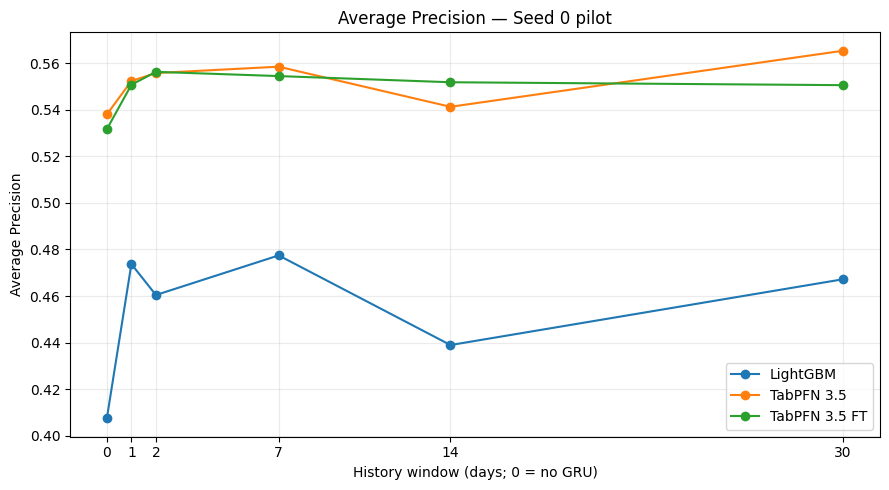

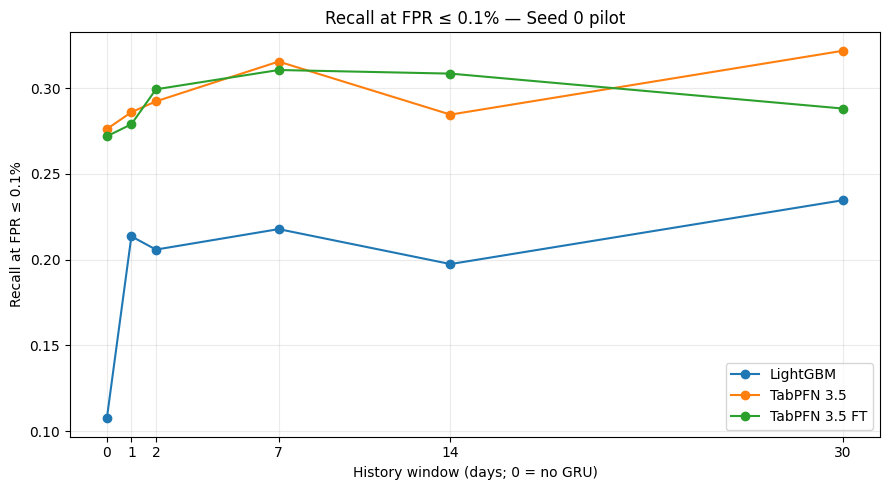

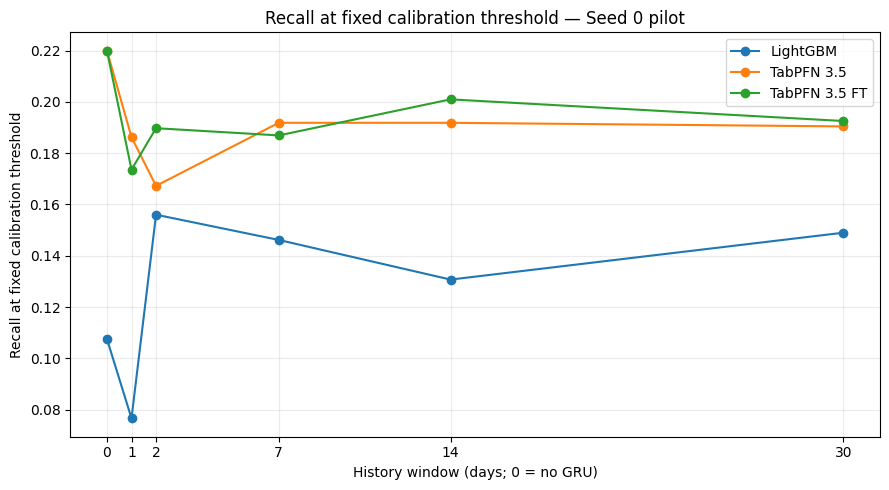

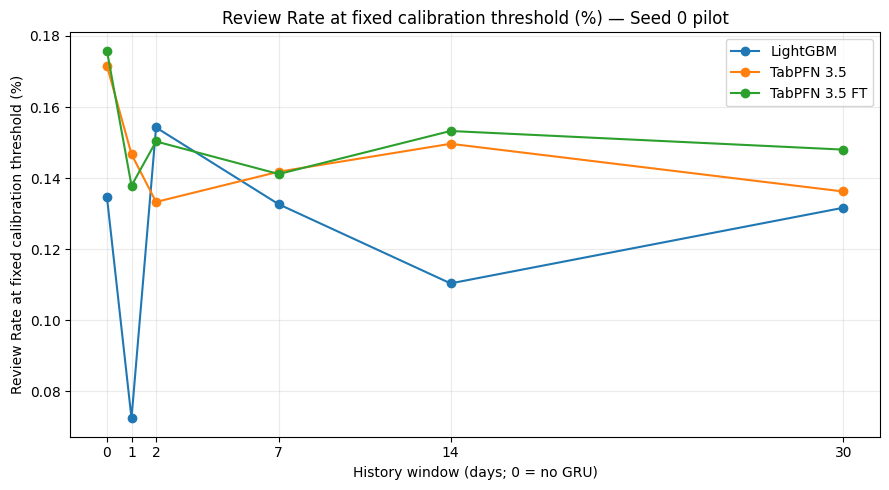

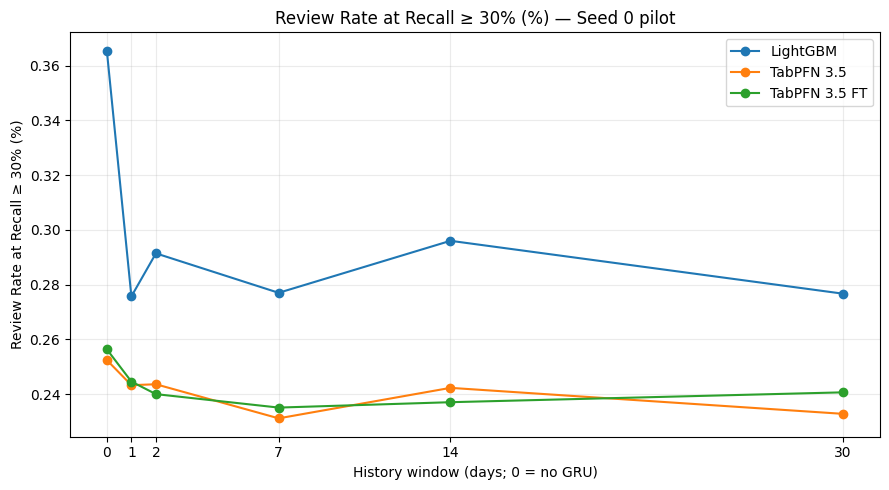

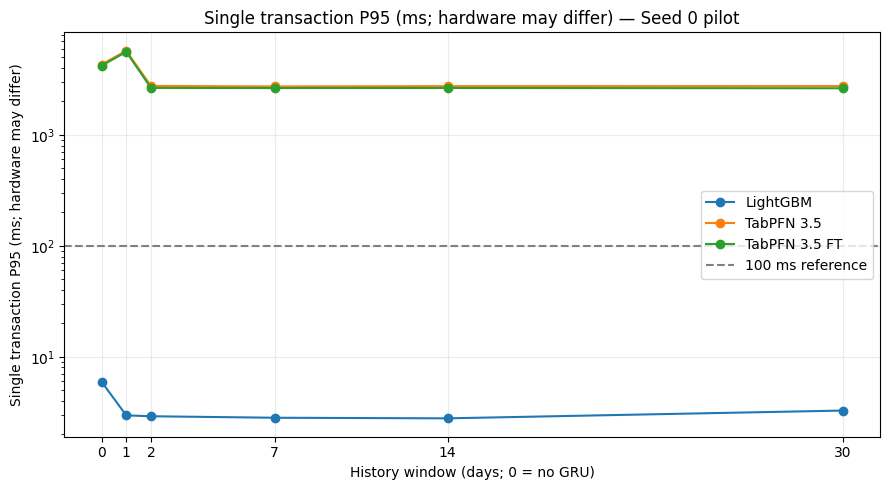

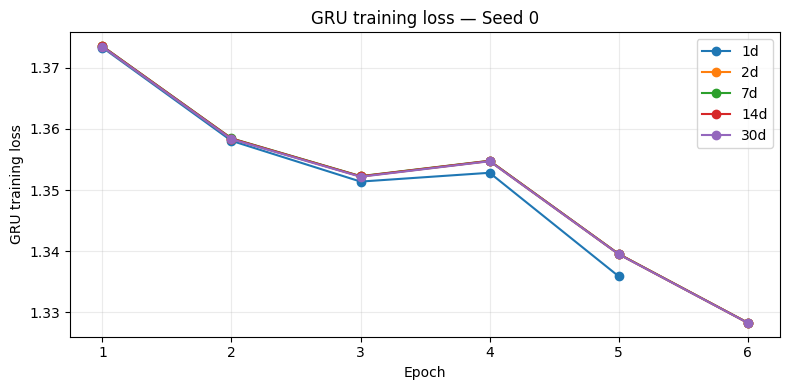

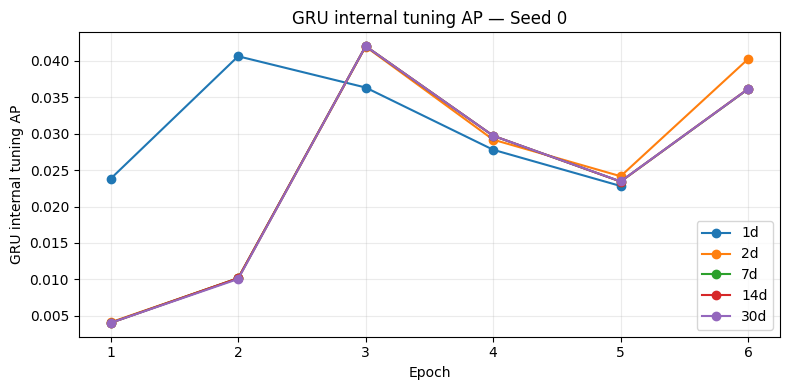

,epochs,best_tune_AP
days,,
1,5,0.04064
2,6,0.04196
7,6,0.04203
14,6,0.04202
30,6,0.04203


저장 경로: /content/drive/MyDrive/26-2_AI_project/processed/full/gru_tabpfn35_original_daily_v2_full/pilot_seed0
단일 seed 예비 실험: 최적 기간 확정/강건성 주장 금지. Test 미사용.


In [17]:
# 10. 예비 실험 자동 요약 — 기존 Stage A 및 전체 실험 요약은 덮어쓰지 않음
res=collect()
assert not res.duplicated(['days','seed','model']).any()
days=[0]+RUN_DAYS
pilot=res[res.seed.isin(RUN_SEEDS)&res.days.isin(days)].copy().sort_values(['days','model'])
assert len(pilot)==len(days)*len(MODELS)*len(RUN_SEEDS), '예비 실험 미완료'
write_csv(PILOT/'pilot_seed0.csv',pilot)
cols=['days','model','features','gru_train_sec','gru_tune_AP','AP','Recall_at_FPR','fixed_recall','fixed_fpr','review_rate_fixed','review_rate_at_target_recall','p95_ms']
display(pilot[cols].round(5))
metrics_paired=['AP','Recall_at_FPR','review_rate_fixed','review_rate_at_target_recall']
b=pilot[pilot.days.eq(0)][['seed','model']+metrics_paired]
delta=pilot.merge(b,on=['seed','model'],suffixes=('','_baseline'),validate='many_to_one')
for k in metrics_paired: delta[k+'_change_pp']=100*(delta[k]-delta[k+'_baseline'])
write_csv(PILOT/'paired_vs_no_gru_seed0.csv',delta)
display(delta[['days','model','AP_change_pp','Recall_at_FPR_change_pp','review_rate_fixed_change_pp']].round(4))
for k,title in [('AP','Average Precision'),('Recall_at_FPR','Recall at FPR ≤ 0.1%'),('fixed_recall','Recall at fixed calibration threshold'),('review_rate_fixed','Review Rate at fixed calibration threshold (%)'),('review_rate_at_target_recall','Review Rate at Recall ≥ 30% (%)'),('p95_ms','Single transaction P95 (ms; hardware may differ)')]:
    fig,ax=plt.subplots(figsize=(9,5))
    for m in MODELS:
        g=pilot[pilot.model.eq(m)].sort_values('days')
        ax.plot(g.days,g[k]*(100 if k.startswith('review_rate_') else 1),marker='o',label=m)
    if k=='p95_ms': ax.set_yscale('log'); ax.axhline(LATENCY_LIMIT,ls='--',color='gray',label='100 ms reference')
    ax.set_xticks(days); ax.set_xlabel('History window (days; 0 = no GRU)'); ax.set_ylabel(title); ax.set_title(title+' — Seed 0 pilot'); ax.grid(alpha=.25); ax.legend(); fig.tight_layout(); fig.savefig(PILOT/f'pilot_seed0_{k}.png',dpi=180); plt.show(); plt.close(fig)
# GRU 자체 학습 곡선: 훈련 loss와 내부 tune AP. 기존 체크포인트 기록도 재사용.
hist=[]
for d in RUN_DAYS:
    path=OUT/'embeddings'/f'd{d}_s0.json'
    if path.exists():
        info=json.loads(path.read_text())
        hist.extend(dict(days=d,seed=0,**h) for h in info['history'])
    else: print('GRU history 누락:',path)
if hist:
    h=pd.DataFrame(hist); write_csv(PILOT/'gru_history_seed0.csv',h)
    for k,title in [('loss','GRU training loss'),('tune_AP','GRU internal tuning AP')]:
        fig,ax=plt.subplots(figsize=(8,4))
        for d,g in h.groupby('days'): ax.plot(g.epoch,g[k],marker='o',label=f'{d}d')
        ax.set_xlabel('Epoch'); ax.set_ylabel(title); ax.set_title(title+' — Seed 0'); ax.grid(alpha=.25); ax.legend(); fig.tight_layout(); fig.savefig(PILOT/f'gru_seed0_{k}.png',dpi=180); plt.show(); plt.close(fig)
    display(h.groupby('days').agg(epochs=('epoch','max'),best_tune_AP=('tune_AP','max')).round(5))
print('저장 경로:',PILOT)
print('단일 seed 예비 실험: 최적 기간 확정/강건성 주장 금지. Test 미사용.')


## 해석 및 제한
- Seed 0의 동일 baseline 대비 AP/Recall 변화와 GRU 내부 tune AP, loss를 확인한다. 학습 loss 하락만으로 성능 향상을 입증할 수 없다.
- 고정 threshold Review Rate는 fixed_recall/fixed_fpr와 함께 해석한다. Recall_at_FPR는 평가 ROC 진단용으로 별개다.
- 이전과 새 하드웨어가 다르면 시간 지표를 통제된 비교로 해석하지 않는다. 기존 기록에는 session ID가 있고 새 기록은 GPU/CPU도 추가 저장한다. 기존 encoder 시간은 최초 학습 세션의 기록이다.
- Seed 0 결과는 가설 탐색용이다. 이후 5 seed 및 독립 Test 검증이 필요하다.
- 기존 학습 행을 encoder와 classifier가 공유하는 원본 설계이므로 표현 과적합 가능성은 남아 있다.
- Colab 종료 시 완료된 JSON/NPZ 및 GRU 체크포인트는 보존된다. 미완료 분류기는 다시 학습한다.
